# Neftel 2019 GBM — 02 · Manifold & trajectory

Fit a scFates principal graph to the 10x malignant manifold. The geometry (branching vs non-branching) is decided by biology — whether Gast and pSom form two competing arms — not by an ElPiGraph node count. We score the three developmental modules, read their spatial relationship, fit a **curve** (non-branching topology), verify it is fold-free, root it at the Gast/pSom-high developmental origin, and confirm continuity on an embedding the curve was not fit on.

In [1]:
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold; score developmental modules
`score_genes` for Gast/pSom/Crest against the union control pool, then graph-smooth the scores (kNN-connectivity averaging) so geography is read from a de-noised field rather than per-cell noise.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u, s, vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 10229 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.41
Gast: 76/81 genes present
pSom: 90/98 genes present
Crest: 102/104 genes present


### Geometry from biology: is there a Gast↔pSom cross-repression axis?
A **branching** case needs Gast and pSom to anti-correlate (two competing arms). If they co-vary and both oppose Crest, the programs are present but collapsed onto one axis — the **non-branching** case (§1) — and a curve is the correct topology. We also confirm proliferation is orthogonal to the axis.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nGast/pSom co-vary (r>0) and both oppose Crest -> single collapsed axis, NON-BRANCHING.')

adata.obs['cyc_score'] = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).combine(
                         pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0), max)
print('\nproliferation orthogonality (corr of cycling score with modules):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  cyc_score vs {m}: r = {np.corrcoef(adata.obs.cyc_score, adata.obs[m])[0,1]:+.2f}')
print('\nper-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile across compartments:', frac)
print('-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.79
  Crest_sm vs Gast_sm: r = -0.89
  Crest_sm vs pSom_sm: r = -0.90

Gast/pSom co-vary (r>0) and both oppose Crest -> single collapsed axis, NON-BRANCHING.

proliferation orthogonality (corr of cycling score with modules):
  cyc_score vs Gast_sm: r = -0.12
  cyc_score vs pSom_sm: r = +0.19
  cyc_score vs Crest_sm: r = -0.15

per-compartment smoothed developmental means:
                  Gast_sm  pSom_sm  Crest_sm
compartment                                 
Cycling-enriched   0.0350   0.0866   -0.0663
Embryonic          0.0124   0.0656   -0.0426

Crest-high decile across compartments: {'Embryonic': 0.99, 'Cycling-enriched': 0.01}
-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).


### Fit the curve and verify it is fold-free
A curve is only valid if it does not fold back through the cloud. `fold_diag` reports tips, forks, and the minimum self-approach of graph-distant nodes relative to the median edge length (>1 = fold-free). We assert zero forks and no fold before trusting the pseudotime.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.81 (>1 = fold-free)


### Root from developmental order, compute pseudotime
Score each tip by its smoothed module means and root at the Gast/pSom-high, Crest-low tip — the developmental origin. Crest is a *late* readout, so it is never the root.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('\ngradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho, p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=+0.0429 pSom=+0.0923 Crest=-0.0709
tip 2: Gast=+0.0093 pSom=+0.0561 Crest=-0.0367
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.375 p=0.0e+00
  pSom_sm: rho=-0.739 p=0.0e+00
  Crest_sm: rho=+0.550 p=0.0e+00
  cyc_score: rho=-0.167 p=6.5e-65


### Continuity off an independent embedding
The curve was fit on the UMAP, so continuity cannot be judged with a UMAP-neighbour metric (blind to a fold in that same UMAP — the Kürten failure mode). We check pseudotime against a **diffusion-map** component, an embedding the curve never touched.

In [7]:
sc.tl.diffmap(sub, n_comps=15)
dc1 = sub.obsm['X_diffmap'][:,1]
rho_dc, _ = spearmanr(t, dc1)
print(f'continuity: corr(pseudotime, diffusion DC1) = {rho_dc:+.2f} on an independent embedding')
print('monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.')

continuity: corr(pseudotime, diffusion DC1) = +0.96 on an independent embedding
monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.


### Orient to the house linear layout (pseudotime left → right)

In [8]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])        # identity: already horizontal
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:                                         # ensure low pt -> left
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: identity (already horizontal); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: identity (already horizontal); corr(x_lin, pseudotime) = +0.97


### Render the fitted curve on the embedding (catch folds visually)

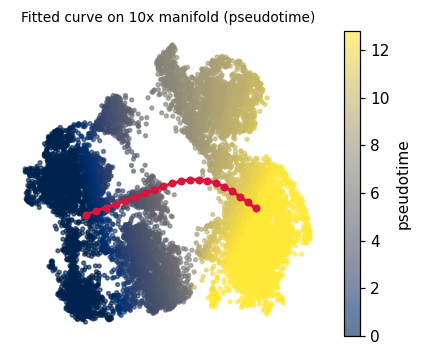

In [9]:
F = np.asarray(sub.uns['graph']['F']); Bc = np.asarray(sub.uns['graph']['B'])
ii, jj = np.where(np.triu(Bc>0))
fig, ax = plt.subplots(figsize=(4.6, 3.6))
sca = ax.scatter(sub.obsm['X_umap'][:,0], sub.obsm['X_umap'][:,1], c=t, cmap='cividis', s=6, alpha=.6)
for a, b in zip(ii, jj):
    ax.plot([F[0,a],F[0,b]], [F[1,a],F[1,b]], '-', color='crimson', lw=2, zorder=5)
ax.scatter(F[0], F[1], c='crimson', s=18, zorder=6)
ax.axis('off'); ax.set_title('Fitted curve on 10x manifold (pseudotime)', size=9)
plt.colorbar(sca, ax=ax, label='pseudotime'); plt.show()

### Deliverable — `manifold.pdf` + `manifold.h5ad`

saved manifold.h5ad + manifold.pdf


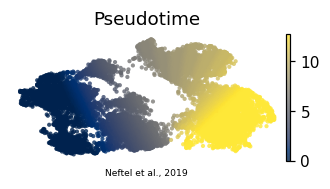

In [10]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:,0], [0.3,99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Neftel et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf')